# DDPM Diffusion Model + FTCNN-ViT Fusion
## Replacing StyleGAN2-ADA with Denoising Diffusion Probabilistic Models (DDPM)

### Why Diffusion over GAN for this task?

| Property | GAN (StyleGAN2-ADA) | DDPM (Chosen) |
|---|---|---|
| Training stability | Adversarial — can collapse | Stable — fixed noise schedule |
| Mode coverage | Often drops rare modes | Near-complete coverage |
| Sample diversity | Moderate (mode collapse risk) | High — samples full data distribution |
| Small dataset (<1000) | Needs ADA tricks | Works well via classifier-free guidance |
| Evaluation (FID) | Competitive but unpredictable | State-of-the-art across benchmarks |
| Code complexity | Needs two networks (G+D) | Single UNet with noise schedule |

### Different Diffusion Model Variants Considered

| Model | Key Idea | Why NOT chosen here |
|---|---|---|
| **DDPM** ✅ CHOSEN | Gaussian noise schedule, UNet denoiser | Best balance of quality & simplicity |
| DDIM | Deterministic sampling, 10x faster inference | Slightly lower diversity; best for inference speed |
| Stable Diffusion (LDM) | Latent-space diffusion + text conditioning | Needs 4+ GB VRAM just for base model; overkill for 224×224 binary task |
| Score-SDE | Continuous-time SDE framework | Research-grade; harder to tune |
| DALL-E 2 / Imagen | Cascaded diffusion + CLIP | Cloud API only; not trainable on Kaggle T4 |
| Consistency Models | Single-step distillation | Still experimental; needs a teacher DDPM first |

### ✅ Why DDPM was chosen
- Runs **fully on a single Kaggle T4** (16 GB VRAM)
- Works well on **small datasets (< 1000 images)** by learning a noise schedule
- **Class-conditional generation** is easy: just concat a class embedding to the UNet
- No discriminator → **no adversarial instability**
- Original DDPM paper (Ho et al., NeurIPS 2020) shows near-GAN quality on 256×256
- Well-tested open-source implementations (Hugging Face `diffusers`)

---
### Pipeline Overview
```
Raw Images → Preprocessing → [DDPM Fine-tune] → Synthetic Images
                                    ↓
             Augmented Training Set (Real + Synthetic)
                                    ↓
              FTCNN + ViT Fusion Classifier → Evaluate
```

ZIP created at:
/kaggle/working/synthetic_images.zip


## Cell 1 — Install Dependencies

In [ ]:
# Kaggle-compatible installation
import subprocess, sys

def pip_install(*pkgs):
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--upgrade", *pkgs])

pip_install(
    "huggingface_hub==0.20.3",
    "diffusers==0.27.2",
    "transformers==4.40.2",
    "accelerate==0.29.3",
    "safetensors"
)
print("✅ Compatible packages installed. Restart the Kaggle session after this cell.")


## Cell 2 — Imports & Global Config

In [1]:
import diffusers
import huggingface_hub
import transformers
import accelerate

print("diffusers:", diffusers.__version__)
print("huggingface_hub:", huggingface_hub.__version__)
print("transformers:", transformers.__version__)
print("accelerate:", accelerate.__version__)

The cache for model files in Transformers v4.22.0 has been updated. Migrating your old cache. This is a one-time only operation. You can interrupt this and resume the migration later on by calling `transformers.utils.move_cache()`.


0it [00:00, ?it/s]

diffusers: 0.27.2
huggingface_hub: 0.20.3
transformers: 4.40.2
accelerate: 0.29.3


In [2]:
import os, random, warnings, math
import numpy as np
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from PIL import Image
warnings.filterwarnings('ignore')

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
/
import tensorflow as tf
from tensorflow.keras import layers, Model, optimizers, callbacks
from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_curve, auc, precision_recall_curve
)
from sklearn.utils import shuffle as sk_shuffle

# ── Diffusers ─────────────────────────────────────────────────────────────────
from diffusers import DDPMScheduler, UNet2DModel
from diffusers.optimization import get_cosine_schedule_with_warmup

print('TensorFlow :', tf.__version__)
print('PyTorch    :', torch.__version__)
print('TF GPU     :', tf.config.list_physical_devices('GPU'))
print('PT GPU     :', torch.cuda.is_available(),
      torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'N/A')

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
SEED   = 42
random.seed(SEED); np.random.seed(SEED)
tf.random.set_seed(SEED); torch.manual_seed(SEED)
print('Device:', DEVICE)

TensorFlow : 2.20.0
PyTorch    : 2.10.0+cu128
TF GPU     : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
PT GPU     : True Tesla T4
Device: cuda


In [3]:
# ── Paths ──────────────────────────────────────────────────────────────────────
KAGGLE_DATA = '/kaggle/input/datasets/ckay16/accident-detection-from-cctv-footage/data'
TRAIN_DIR   = os.path.join(KAGGLE_DATA, 'train')
VAL_DIR     = os.path.join(KAGGLE_DATA, 'val')
TEST_DIR    = os.path.join(KAGGLE_DATA, 'test')

OUTPUT_DIR  = '/kaggle/working/outputs'
MODEL_DIR   = '/kaggle/working/models'
DIFF_DIR    = '/kaggle/working/diffusion'
SYNTH_DIR   = '/kaggle/working/synthetic'

for d in [
    OUTPUT_DIR, MODEL_DIR, DIFF_DIR,
    os.path.join(DIFF_DIR, 'checkpoints'),
    SYNTH_DIR,
    os.path.join(SYNTH_DIR, 'accident'),
    os.path.join(SYNTH_DIR, 'no_accident')
]:
    os.makedirs(d, exist_ok=True)

# ── Image ──────────────────────────────────────────────────────────────────────
IMG_H, IMG_W, IMG_C = 64, 64, 3        # DDPM trained at 64×64 (T4 fits 64 easily)
IMG_SHAPE           = (IMG_H, IMG_W, IMG_C)
CLF_H, CLF_W        = 224, 224         # Classifier still uses 224×224
CLASSES             = ['No Accident', 'Accident']
NUM_CLASSES         = 2

# ── DDPM Hyperparameters ───────────────────────────────────────────────────────
DDPM_EPOCHS        = 150               # Increase to 300 for higher quality
DDPM_BATCH         = 16
DDPM_LR            = 1e-4
NUM_TRAIN_STEPS    = 1000              # T in the noise schedule
N_SYNTHETIC        = 200               # Synthetic images per class to generate
DDPM_IMG_SIZE      = 64

# ── FTCNN-ViT Classifier ───────────────────────────────────────────────────────
BATCH_SIZE    = 32
EPOCHS_HYB    = 50
DROPOUT_FTCNN = 0.5
PATCH_SIZE    = 16
PROJ_DIM      = 64
NUM_HEADS     = 4
NUM_LAYERS    = 8
LR_HYB        = 3e-4

# ── Preprocessing constants (Eq. 3-5 from paper) ──────────────────────────────
SAT_FACTOR   = 1.5
BRTNS_FACTOR = 1.2
CONT_FACTOR  = 1.3

print('Config OK.')

Config OK.


## Cell 3 — Data Preprocessing (Eq. 3-5)

In [4]:
def resize_image(img, h=CLF_H, w=CLF_W):
    return cv2.resize(img, (w, h), interpolation=cv2.INTER_AREA)

def enhance_image(img):
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV).astype(np.float32)
    hsv[:,:,1] = np.clip(hsv[:,:,1] * SAT_FACTOR, 0, 255)
    out = cv2.cvtColor(hsv.astype(np.uint8), cv2.COLOR_HSV2BGR)
    out = np.clip(out.astype(np.float32) * BRTNS_FACTOR, 0, 255).astype(np.uint8)
    out = np.clip(CONT_FACTOR * out.astype(np.float32) + 128*(1-CONT_FACTOR),
                  0, 255).astype(np.uint8)
    return out

def normalize_image(img):
    return img.astype(np.float32) / 255.0

def transform_image(img, h=CLF_H, w=CLF_W):
    return normalize_image(enhance_image(resize_image(img, h, w)))

def load_split(split_dir, h=CLF_H, w=CLF_W):
    X, y, label_map = [], [], {}
    for entry in os.scandir(split_dir):
        if not entry.is_dir(): continue
        n = entry.name.lower()
        label_map[entry.path] = 0 if ('non' in n or 'no ' in n or 'no_' in n) else 1
    supported = ('.jpg', '.jpeg', '.png', '.bmp')
    for folder, label in label_map.items():
        for fname in os.listdir(folder):
            if not fname.lower().endswith(supported): continue
            img = cv2.imread(os.path.join(folder, fname))
            if img is None: continue
            X.append(transform_image(img, h, w))
            y.append(label)
    X, y = np.array(X, dtype=np.float32), np.array(y, dtype=np.int32)
    idx = np.random.permutation(len(X))
    return X[idx], y[idx]

print('Loading dataset ...')
X_train, y_train = load_split(TRAIN_DIR)
X_val,   y_val   = load_split(VAL_DIR)
X_test,  y_test  = load_split(TEST_DIR)
for name, X, y in [('train', X_train, y_train),
                    ('val',   X_val,   y_val),
                    ('test',  X_test,  y_test)]:
    print(f'  {name:5s}: {len(X):5d} | accident={y.sum()} | no-acc={(y==0).sum()}')

Loading dataset ...
  train:   791 | accident=369 | no-acc=422
  val  :    98 | accident=46 | no-acc=52
  test :   100 | accident=47 | no-acc=53


## Cell 4 — DDPM Dataset (PyTorch) — 64×64 images for diffusion training

In [5]:
class AccidentDiffusionDataset(Dataset):
    """
    PyTorch Dataset for DDPM training.
    Loads images at 64×64 and returns:
        image  : tensor [3, 64, 64] in [-1, 1]   (DDPM standard)
        label  : int 0 or 1                       (for class-conditional guidance)
    """
    def __init__(self, split_dir, img_size=DDPM_IMG_SIZE, augment=True):
        self.paths  = []
        self.labels = []
        self.img_size = img_size
        self.augment  = augment

        label_map = {}
        for entry in os.scandir(split_dir):
            if not entry.is_dir(): continue
            n = entry.name.lower()
            label_map[entry.path] = 0 if ('non' in n or 'no ' in n or 'no_' in n) else 1

        supported = ('.jpg', '.jpeg', '.png', '.bmp')
        for folder, label in label_map.items():
            for fname in os.listdir(folder):
                if fname.lower().endswith(supported):
                    self.paths.append(os.path.join(folder, fname))
                    self.labels.append(label)

        # Augmentations for diffusion training
        self.aug_tfm = transforms.Compose([
            transforms.RandomHorizontalFlip(),
            transforms.RandomRotation(10),
            transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1),
        ])
        self.to_tensor = transforms.Compose([
            transforms.Resize((img_size, img_size)),
            transforms.ToTensor(),
            transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])  # → [-1, 1]
        ])

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        img = Image.open(self.paths[idx]).convert('RGB')
        if self.augment:
            img = self.aug_tfm(img)
        img = self.to_tensor(img)
        label = torch.tensor(self.labels[idx], dtype=torch.long)
        return img, label


# Build per-class datasets for class-conditional training
train_ds_acc  = AccidentDiffusionDataset(TRAIN_DIR)
train_ds_acc_only  = [(img, lbl) for img, lbl in train_ds_acc if lbl == 1]
train_ds_nonacc    = [(img, lbl) for img, lbl in train_ds_acc if lbl == 0]
print(f'Diffusion dataset — Accident: {len(train_ds_acc_only)} | No-Accident: {len(train_ds_nonacc)}')
print(f'Total for joint training: {len(train_ds_acc)}')

Diffusion dataset — Accident: 369 | No-Accident: 422
Total for joint training: 791


## Cell 5 — Build DDPM UNet (Hugging Face `diffusers`)

`UNet2DModel` is the standard architecture from:
> *Denoising Diffusion Probabilistic Models* — Ho et al. NeurIPS 2020

It is a U-Net with:
- **Residual blocks** + **GroupNorm** in the encoder/decoder
- **Self-attention** layers at lower resolutions
- **Sinusoidal timestep embedding** injected at every residual block
- **Class embedding** (optional) added to timestep embedding for class-conditional generation

In [6]:
def build_ddpm_unet(img_size=DDPM_IMG_SIZE, num_classes=2):
    """
    Class-conditional UNet2DModel.
    class_embed_type='identity' lets us inject a class embedding vector
    the same way timestep embeddings are injected.
    """
    model = UNet2DModel(
        sample_size      = img_size,           # 64×64
        in_channels      = 3,
        out_channels     = 3,
        layers_per_block = 2,
        block_out_channels = (128, 128, 256, 256, 512, 512),
        down_block_types = (
            'DownBlock2D',       # 64 → 32
            'DownBlock2D',
            'DownBlock2D',       # 32 → 16
            'AttnDownBlock2D',   # 16 → 8  (attention)
            'AttnDownBlock2D',   # 8  → 4
            'AttnDownBlock2D',   # 4  → 2
        ),
        up_block_types = (
            'AttnUpBlock2D',
            'AttnUpBlock2D',
            'AttnUpBlock2D',
            'UpBlock2D',
            'UpBlock2D',
            'UpBlock2D',
        ),
        num_class_embeds = num_classes,        # Class-conditional: 0=No-Accident, 1=Accident
    )
    return model

unet = build_ddpm_unet().to(DEVICE)
noise_scheduler = DDPMScheduler(
    num_train_timesteps = NUM_TRAIN_STEPS,
    beta_schedule       = 'linear',            # Linear schedule (Ho et al. default)
    prediction_type     = 'epsilon',           # Predict added noise (ε-prediction)
)

total_params = sum(p.numel() for p in unet.parameters() if p.requires_grad)
print(f'UNet parameters : {total_params:,}')
print(f'Noise schedule  : {noise_scheduler.config.beta_schedule}')
print(f'Timesteps T     : {NUM_TRAIN_STEPS}')

UNet parameters : 120,250,883
Noise schedule  : linear
Timesteps T     : 1000


## Cell 6 — DDPM Training Loop

### How DDPM Training Works (Algorithm 1 in Ho et al.)
```
For each batch:
    1. Sample clean images x₀
    2. Sample random timesteps t ~ Uniform(0, T)
    3. Sample Gaussian noise ε ~ N(0, I)
    4. Compute noisy images xₜ = √ᾱₜ·x₀ + √(1-ᾱₜ)·ε
    5. Predict ε̂ = UNet(xₜ, t, class_label)
    6. Loss = MSE(ε, ε̂)
    7. Backprop & update UNet weights
```

In [7]:
def train_ddpm(
    model, scheduler, dataset,
    epochs=DDPM_EPOCHS,
    batch_size=DDPM_BATCH,
    lr=DDPM_LR,
    save_dir=DIFF_DIR
):
    loader = DataLoader(
        dataset, batch_size=batch_size,
        shuffle=True, num_workers=2, pin_memory=True
    )

    optimizer = torch.optim.AdamW(model.parameters(), lr=lr)
    lr_scheduler = get_cosine_schedule_with_warmup(
        optimizer,
        num_warmup_steps  = len(loader) * 5,        # Warm up for 5 epochs
        num_training_steps= len(loader) * epochs,
    )

    model.train()
    loss_history = []

    for epoch in range(1, epochs + 1):
        epoch_loss = 0.0
        for step, (clean_images, class_labels) in enumerate(loader):
            clean_images  = clean_images.to(DEVICE)         # [B, 3, 64, 64]
            class_labels  = class_labels.to(DEVICE)         # [B]

            # Step 1 — Sample random timesteps
            bs = clean_images.shape[0]
            timesteps = torch.randint(
                0, scheduler.config.num_train_timesteps,
                (bs,), device=DEVICE
            ).long()

            # Step 2 — Add noise to clean images (forward process)
            noise = torch.randn_like(clean_images)
            noisy_images = scheduler.add_noise(clean_images, noise, timesteps)

            # Step 3 — Predict the noise
            noise_pred = model(
                noisy_images,
                timesteps,
                class_labels=class_labels     # Class conditioning
            ).sample

            # Step 4 — ε-prediction loss (MSE between true noise & predicted noise)
            loss = F.mse_loss(noise_pred, noise)

            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)  # Gradient clip
            optimizer.step()
            lr_scheduler.step()

            epoch_loss += loss.item()

        avg_loss = epoch_loss / len(loader)
        loss_history.append(avg_loss)

        if epoch % 10 == 0 or epoch == 1:
            print(f'  Epoch [{epoch:3d}/{epochs}]  Loss: {avg_loss:.5f}  '
                  f'LR: {lr_scheduler.get_last_lr()[0]:.6f}')

        # Save checkpoint every 25 epochs
        if epoch % 25 == 0:
            ckpt_path = os.path.join(save_dir, 'checkpoints', f'unet_epoch{epoch}.pt')
            torch.save(model.state_dict(), ckpt_path)
            print(f'  💾 Checkpoint saved → {ckpt_path}')

    # Save final model
    final_path = os.path.join(save_dir, 'unet_final.pt')
    torch.save(model.state_dict(), final_path)
    print(f'\n✅ Training complete. Final model → {final_path}')
    return loss_history


print(f'Starting DDPM training for {DDPM_EPOCHS} epochs ...')
print(f'  Image size : {DDPM_IMG_SIZE}×{DDPM_IMG_SIZE}')
print(f'  Batch size : {DDPM_BATCH}')
print(f'  Timesteps T: {NUM_TRAIN_STEPS}')
print(f'  Device     : {DEVICE}')
print('-' * 55)

loss_hist = train_ddpm(unet, noise_scheduler, train_ds_acc)

Starting DDPM training for 150 epochs ...
  Image size : 64×64
  Batch size : 16
  Timesteps T: 1000
  Device     : cuda
-------------------------------------------------------
  Epoch [  1/150]  Loss: 0.82975  LR: 0.000020
  Epoch [ 10/150]  Loss: 0.03897  LR: 0.000100
  Epoch [ 20/150]  Loss: 0.02753  LR: 0.000097
  💾 Checkpoint saved → /kaggle/working/diffusion/checkpoints/unet_epoch25.pt
  Epoch [ 30/150]  Loss: 0.02644  LR: 0.000093
  Epoch [ 40/150]  Loss: 0.02428  LR: 0.000086
  Epoch [ 50/150]  Loss: 0.02564  LR: 0.000078
  💾 Checkpoint saved → /kaggle/working/diffusion/checkpoints/unet_epoch50.pt
  Epoch [ 60/150]  Loss: 0.02261  LR: 0.000069
  Epoch [ 70/150]  Loss: 0.02503  LR: 0.000058
  💾 Checkpoint saved → /kaggle/working/diffusion/checkpoints/unet_epoch75.pt
  Epoch [ 80/150]  Loss: 0.02034  LR: 0.000047
  Epoch [ 90/150]  Loss: 0.02554  LR: 0.000037
  Epoch [100/150]  Loss: 0.02036  LR: 0.000027
  💾 Checkpoint saved → /kaggle/working/diffusion/checkpoints/unet_epoch100.

## Cell 7 — Plot DDPM Training Loss

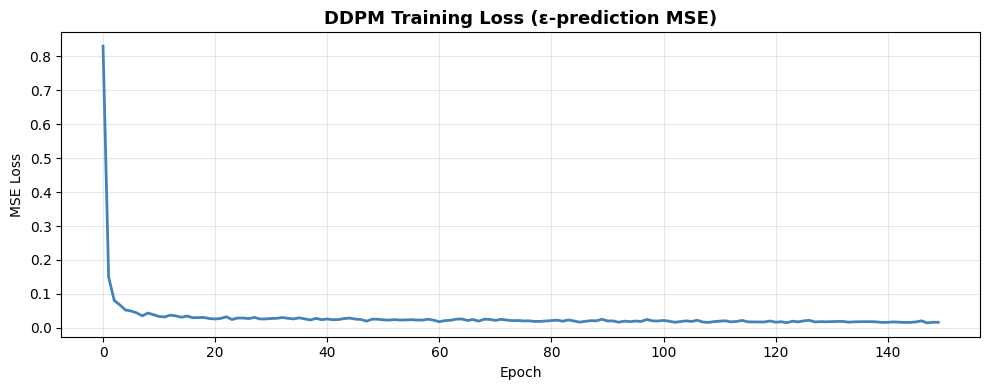

Loss curve saved.


In [8]:
plt.figure(figsize=(10, 4))
plt.plot(loss_hist, color='steelblue', lw=2)
plt.xlabel('Epoch'); plt.ylabel('MSE Loss')
plt.title('DDPM Training Loss (ε-prediction MSE)', fontsize=13, fontweight='bold')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'ddpm_loss_curve.png'), dpi=150)
plt.show()
print('Loss curve saved.')

## Cell 8 — DDPM Sampling (Reverse Diffusion) + Synthetic Image Generation

### How DDPM Sampling Works (Algorithm 2 in Ho et al.)
```
Start from pure noise: xₜ ~ N(0, I)
For t = T, T-1, ..., 1:
    ε̂ = UNet(xₜ, t, class_label)
    μ̂ₜ = (1/√αₜ) · (xₜ − βₜ/√(1−ᾱₜ) · ε̂)
    z ~ N(0,I)  if t > 1 else z = 0
    x_{t-1} = μ̂ₜ + √βₜ · z
Return x₀
```

In [9]:
@torch.no_grad()
def generate_samples(
    model, scheduler, class_label,
    n_samples=16, img_size=DDPM_IMG_SIZE,
    device=DEVICE
):
    """
    Generate `n_samples` images for a given class_label (0 or 1)
    using the DDPM reverse diffusion process.
    """
    model.eval()

    # Start from random Gaussian noise
    images = torch.randn(
        n_samples, 3, img_size, img_size,
        device=device
    )
    labels = torch.full((n_samples,), class_label, dtype=torch.long, device=device)

    # Set the scheduler to full T timesteps for inference
    scheduler.set_timesteps(NUM_TRAIN_STEPS)

    for t in scheduler.timesteps:  # T → 0
        # Predict noise
        model_output = model(images, t, class_labels=labels).sample
        # Denoise one step
        images = scheduler.step(model_output, t, images).prev_sample

    # Clamp to [-1, 1] then convert to [0, 255] uint8
    images = (images.clamp(-1, 1) + 1) / 2.0       # → [0, 1]
    images = (images * 255).byte().cpu().numpy()     # → [0, 255]
    images = images.transpose(0, 2, 3, 1)            # [B, H, W, C]
    return images


def save_synthetic_images(model, scheduler, n_per_class=N_SYNTHETIC):
    """Generate and save synthetic images for both classes."""
    class_names = ['no_accident', 'accident']
    counts = {}

    for cls_idx, cls_name in enumerate(class_names):
        print(f'  Generating {n_per_class} {cls_name} images ...')
        save_folder = os.path.join(SYNTH_DIR, cls_name)
        os.makedirs(save_folder, exist_ok=True)

        generated = 0
        while generated < n_per_class:
            batch_size = min(16, n_per_class - generated)
            imgs = generate_samples(
                model, scheduler,
                class_label=cls_idx,
                n_samples=batch_size
            )
            for img in imgs:
                path = os.path.join(save_folder, f'synth_{generated:04d}.png')
                # Upscale 64×64 → 224×224 for classifier compatibility
                img_large = cv2.resize(
                    img[:, :, ::-1],   # RGB → BGR for cv2
                    (CLF_W, CLF_H),
                    interpolation=cv2.INTER_CUBIC
                )
                cv2.imwrite(path, img_large)
                generated += 1

        counts[cls_name] = generated
        print(f'  ✅ {generated} images saved to {save_folder}')

    return counts


print('Generating synthetic images ...')
save_counts = save_synthetic_images(unet, noise_scheduler)
print('\nSynthetic image count:', save_counts)

Generating synthetic images ...
  Generating 200 no_accident images ...
  ✅ 200 images saved to /kaggle/working/synthetic/no_accident
  Generating 200 accident images ...
  ✅ 200 images saved to /kaggle/working/synthetic/accident

Synthetic image count: {'no_accident': 200, 'accident': 200}


## Cell 9 — Visualise Generated Samples

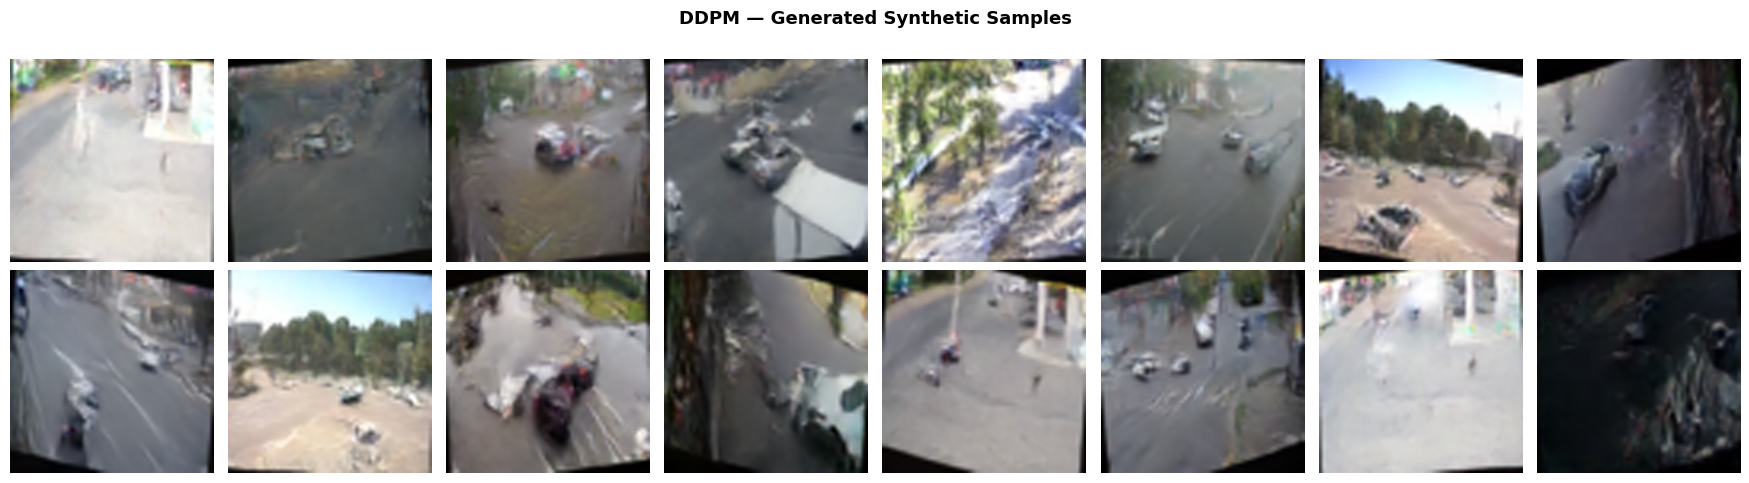

In [10]:
def show_generated_grid(n_each=8):
    fig, axes = plt.subplots(2, n_each, figsize=(2.2 * n_each, 5))
    row_labels = ['No Accident (synthetic)', 'Accident (synthetic)']

    for row_idx, cls_name in enumerate(['no_accident', 'accident']):
        folder = os.path.join(SYNTH_DIR, cls_name)
        files  = sorted(os.listdir(folder))[:n_each]
        for col_idx, fname in enumerate(files):
            img = cv2.imread(os.path.join(folder, fname))
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            axes[row_idx, col_idx].imshow(img)
            axes[row_idx, col_idx].axis('off')
        axes[row_idx, 0].set_ylabel(row_labels[row_idx], fontsize=9, rotation=90)

    plt.suptitle('DDPM — Generated Synthetic Samples',
                 fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, 'ddpm_samples.png'), dpi=150)
    plt.show()

show_generated_grid()

## Cell 10 — Load Synthetic Data & Augment Training Set

In [11]:
def load_synthetic(synth_dir, h=CLF_H, w=CLF_W):
    X_syn, y_syn = [], []
    for cls_idx, cls_name in enumerate(['no_accident', 'accident']):
        folder = os.path.join(synth_dir, cls_name)
        if not os.path.isdir(folder): continue
        for fname in os.listdir(folder):
            if not fname.lower().endswith('.png'): continue
            img = cv2.imread(os.path.join(folder, fname))
            if img is None: continue
            img = cv2.resize(img, (w, h), interpolation=cv2.INTER_AREA)
            X_syn.append(normalize_image(img))
            y_syn.append(cls_idx)
    return np.array(X_syn, dtype=np.float32), np.array(y_syn, dtype=np.int32)

X_syn, y_syn = load_synthetic(SYNTH_DIR)
print(f'Synthetic images loaded: {len(X_syn)}')
print(f'  Accident: {y_syn.sum()} | No-Accident: {(y_syn==0).sum()}')

# Combine real + synthetic
X_aug = np.concatenate([X_train, X_syn], axis=0)
y_aug = np.concatenate([y_train, y_syn], axis=0)
X_aug, y_aug = sk_shuffle(X_aug, y_aug, random_state=SEED)

print(f'\nAugmented training set: {len(X_aug)} images')
print(f'  Accident: {y_aug.sum()} | No-Accident: {(y_aug==0).sum()}')
print(f'  (Original: {len(X_train)} | Added: {len(X_syn)})')

Synthetic images loaded: 400
  Accident: 200 | No-Accident: 200

Augmented training set: 1191 images
  Accident: 569 | No-Accident: 622
  (Original: 791 | Added: 400)


In [24]:
print("PATCH_SIZE =", PATCH_SIZE)
print("CLF_H =", CLF_H)
print("CLF_W =", CLF_W)
n_patches = (CLF_H // PATCH_SIZE) * (CLF_W // PATCH_SIZE)
print("n_patches =", n_patches)

PATCH_SIZE = 16
CLF_H = 224
CLF_W = 224
n_patches = 196


In [25]:
# patches = PatchExtractor(PATCH_SIZE)(inp)
# print(patches.shape)

NameError: name 'inp' is not defined

In [40]:
# DDPM
DDPM_IMG_SIZE = 64

# Classifier
CLF_H = 224
CLF_W = 224
CLF_SHAPE = (224,224,3)

In [41]:
# class PatchExtractor(layers.Layer):
#     def __init__(self, patch_size, **kw):
#         super().__init__(**kw); self.patch_size = patch_size
#     def call(self, images):
#         B=tf.shape(images)[0]; ph=pw=self.patch_size
#         patches=tf.image.extract_patches(images,
#             sizes=[1,ph,pw,1],strides=[1,ph,pw,1],rates=[1,1,1,1],padding='VALID')
#         return tf.reshape(patches,(B,(IMG_H//ph)*(IMG_W//pw),ph*pw*IMG_C))
#     def get_config(self):
#         c=super().get_config(); c['patch_size']=self.patch_size; return c

class PatchExtractor(tf.keras.layers.Layer):
    def __init__(self, patch_size, **kwargs):
        super().__init__(**kwargs)
        self.patch_size = patch_size

    def call(self, images):
        batch_size = tf.shape(images)[0]

        patches = tf.image.extract_patches(
            images=images,
            sizes=[1, self.patch_size, self.patch_size, 1],
            strides=[1, self.patch_size, self.patch_size, 1],
            rates=[1, 1, 1, 1],
            padding="VALID",
        )

        patch_dim = patches.shape[-1]

        patches = tf.reshape(
            patches,
            [batch_size, -1, patch_dim]
        )

        return patches

    def get_config(self):
        config = super().get_config()
        config.update({"patch_size": self.patch_size})
        return config

class PatchEmbedding(layers.Layer):
    def __init__(self,n_patches,proj_dim,**kw):
        super().__init__(**kw)
        self.n_patches=n_patches; self.proj_dim=proj_dim
        self.proj=layers.Dense(proj_dim)
        self.pos_emb=layers.Embedding(n_patches+1,proj_dim)
    def call(self,patches):
        B=tf.shape(patches)[0]; pos=tf.range(0,self.n_patches+1)
        cls=tf.zeros((B,1,self.proj_dim))
        return tf.concat([cls,self.proj(patches)],axis=1)+self.pos_emb(pos)
    def get_config(self):
        c=super().get_config()
        c.update({'n_patches':self.n_patches,'proj_dim':self.proj_dim}); return c

def transformer_block(x,proj_dim,n_heads,drop=0.1):
    x1=layers.LayerNormalization(epsilon=1e-6)(x)
    at=layers.MultiHeadAttention(num_heads=n_heads,
        key_dim=proj_dim//n_heads,dropout=drop)(x1,x1)
    x=layers.Add()([x,at])
    x2=layers.LayerNormalization(epsilon=1e-6)(x)
    x2=layers.Dense(proj_dim*2,activation='gelu')(x2)
    x2=layers.Dropout(drop)(x2)
    x2=layers.Dense(proj_dim)(x2)
    x2=layers.Dropout(drop)(x2)
    return layers.Add()([x,x2])

In [42]:
PATCH_SIZE = 16
CLF_H = 224
CLF_W = 224

n_patches = (CLF_H // PATCH_SIZE) * (CLF_W // PATCH_SIZE)

print(n_patches)

196


In [43]:
x = tf.random.normal((1, 224, 224, 3))
patches = PatchExtractor(16)(x)

print(patches.shape)
print(tf.shape(patches))

(1, 196, 768)
tf.Tensor([  1 196 768], shape=(3,), dtype=int32)


In [44]:
inp = tf.keras.Input((224,224,3))

patches = PatchExtractor(16)(inp)

print("Patch tensor:", patches.shape)

Patch tensor: (None, None, 768)


In [47]:
def build_ftcnn_vit_fusion():
    """
    FTCNN (Table III): Conv32→64→128→256 | Flatten | Dense(512) | Dropout(0.5)
    ViT   (Table IV) : proj_dim=64 | 8 transformer layers | GlobalAvgPool1D
    Fusion           : Concat(1024) | Dense(512) | Dropout(0.5) | Dense(256) | sigmoid
    LR               : 3e-4  (Eq. 13)
    """
    # n_patches=(IMG_H//PATCH_SIZE)*(IMG_W//PATCH_SIZE)  # 196
    
    n_patches = (CLF_H // PATCH_SIZE) * (CLF_W // PATCH_SIZE)
    # inp=layers.Input(shape=IMG_SHAPE,name='image_input')
    inp = layers.Input(shape=CLF_SHAPE, name="image_input")

    # ── FTCNN branch (Table III) ─────────────────────────────────────────────
    f=layers.Conv2D(32,(3,3),padding='same',activation='relu',name='ftcnn_conv1')(inp)
    f=layers.MaxPooling2D((2,2))(f)
    f=layers.Conv2D(64,(3,3),padding='same',activation='relu',name='ftcnn_conv2')(f)
    f=layers.MaxPooling2D((2,2))(f)
    f=layers.Conv2D(128,(3,3),padding='same',activation='relu',name='ftcnn_conv3')(f)
    f=layers.MaxPooling2D((2,2))(f)
    f=layers.Conv2D(256,(3,3),padding='same',activation='relu',name='ftcnn_conv4')(f)
    f=layers.MaxPooling2D((2,2))(f)
    f=layers.Flatten(name='ftcnn_flatten')(f)          # NOT GlobalAvgPool
    f=layers.Dense(512,activation='relu',name='ftcnn_dense512')(f)
    f=layers.Dropout(DROPOUT_FTCNN,name='ftcnn_dropout')(f)

    # ── ViT branch (Table IV) ─────────────────────────────────────────────────
    patches=PatchExtractor(PATCH_SIZE,name='patch_extractor')(inp)
    v=PatchEmbedding(n_patches,PROJ_DIM,name='patch_embedding')(patches)
    for _ in range(NUM_LAYERS):  # 8 layers
        v=transformer_block(v,PROJ_DIM,NUM_HEADS,drop=0.1)
    v=layers.GlobalAveragePooling1D(name='vit_gap')(v)
    v=layers.Dense(512,activation='gelu',name='vit_dense512')(v)
    v=layers.Dropout(0.1,name='vit_dropout')(v)

    # ── Fusion ────────────────────────────────────────────────────────────────
    fused=layers.Concatenate(name='fusion_concat')([f,v])
    fused=layers.Dense(512,activation='gelu',name='fusion_dense512')(fused)
    fused=layers.Dropout(0.5,name='fusion_dropout')(fused)
    fused=layers.Dense(256,activation='gelu',name='fusion_dense256')(fused)
    out=layers.Dense(1,activation='sigmoid',name='output')(fused)

    model=Model(inp,out,name='FTCNN_ViT_Fusion')
    model.compile(optimizer=optimizers.Adam(LR_HYB),
                  loss='binary_crossentropy',metrics=['accuracy'])
    return model

fusion_model=build_ftcnn_vit_fusion()
fusion_model.summary()

Model: "FTCNN_ViT_Fusion"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image_input         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ patch_extractor     │ (None, None, 768) │          0 │ image_input[0][0] │
│ (PatchExtractor)    │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ patch_embedding     │ (None, 197, 64)   │     61,824 │ patch_extractor[… │
│ (PatchEmbedding)    │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 197, 64)   │        128 │ patch_embedding[… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 197, 64)   │     16,640 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_64 (Add)        │ (None, 197, 64)   │          0 │ patch_embedding[… │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 197, 64)   │        128 │ add_64[0][0]      │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_71 (Dense)    │ (None, 197, 128)  │      8,320 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_100         │ (None, 197, 128)  │          0 │ dense_71[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_72 (Dense)    │ (None, 197, 64)   │      8,256 │ dropout_100[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_101         │ (None, 197, 64)   │          0 │ dense_72[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_65 (Add)        │ (None, 197, 64)   │          0 │ add_64[0][0],     │
│                     │                   │            │ dropout_101[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 197, 64)   │        128 │ add_65[0][0]      │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 197, 64)   │     16,640 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_66 (Add)        │ (None, 197, 64)   │          0 │ add_65[0][0],     │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 197, 64)   │        128 │ add_66[0][0]      │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_73 (Dense)    │ (None, 197, 128)  │      8,320 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_103         │ (None, 197, 128)  │          0 │ dense_73[0][0]  

 Total params: 27,098,305 (103.37 MB)

 Trainable params: 27,098,305 (103.37 MB)

 Non-trainable params: 0 (0.00 B)

In [48]:
def make_callbacks(name):
    return [
        callbacks.ModelCheckpoint(
            os.path.join(MODEL_DIR,f'{name}_best.keras'),
            monitor='val_accuracy',save_best_only=True,mode='max',verbose=1),
        callbacks.EarlyStopping(
            monitor='val_loss',patience=12,
            restore_best_weights=True,verbose=1),
        callbacks.ReduceLROnPlateau(
            monitor='val_loss',factor=0.5,patience=5,min_lr=1e-7,verbose=1),
        callbacks.CSVLogger(os.path.join(OUTPUT_DIR,f'{name}_history.csv')),
    ]

print(f'Training FTCNN-ViT Fusion for up to {EPOCHS_HYB} epochs ...')
hist=fusion_model.fit(
    # X_aug, y_aug,
    X_train, y_train,
    validation_data=(X_val,y_val),
    epochs=EPOCHS_HYB,
    batch_size=BATCH_SIZE,
    callbacks=make_callbacks('FTCNN_ViT'),
    verbose=1)
fusion_model.save(os.path.join(MODEL_DIR,'FTCNN_ViT_final.keras'))
print('Training complete.')

Training FTCNN-ViT Fusion for up to 50 epochs ...
Epoch 1/50
 1/25 ━━━━━━━━━━━━━━━━━━━━ 20:03 50s/step - accuracy: 0.4375 - loss: 0.7350

I0000 00:00:1783334736.196324    1747 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.5057 - loss: 0.7393  
Epoch 1: val_accuracy improved from None to 0.53061, saving model to /kaggle/working/models/FTCNN_ViT_best.keras

Epoch 1: finished saving model to /kaggle/working/models/FTCNN_ViT_best.keras
25/25 ━━━━━━━━━━━━━━━━━━━━ 91s 2s/step - accuracy: 0.4994 - loss: 0.7220 - val_accuracy: 0.5306 - val_loss: 0.6875 - learning_rate: 3.0000e-04
Epoch 2/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 101ms/step - accuracy: 0.5162 - loss: 0.7002
Epoch 2: val_accuracy did not improve from 0.53061
25/25 ━━━━━━━━━━━━━━━━━━━━ 3s 109ms/step - accuracy: 0.5133 - loss: 0.6991 - val_accuracy: 0.5306 - val_loss: 0.6892 - learning_rate: 3.0000e-04
Epoch 3/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 99ms/step - accuracy: 0.5586 - loss: 0.6850 
Epoch 3: val_accuracy improved from 0.53061 to 0.64286, saving model to /kaggle/working/models/FTCNN_ViT_best.keras

Epoch 3: finished saving model to /kaggle/working/models/FTCNN_ViT_best.keras
25/25 ━━━━━━━━━━━━━━━━━━━━ 5

## Cell 15 — Training Curves (Fig. 3)

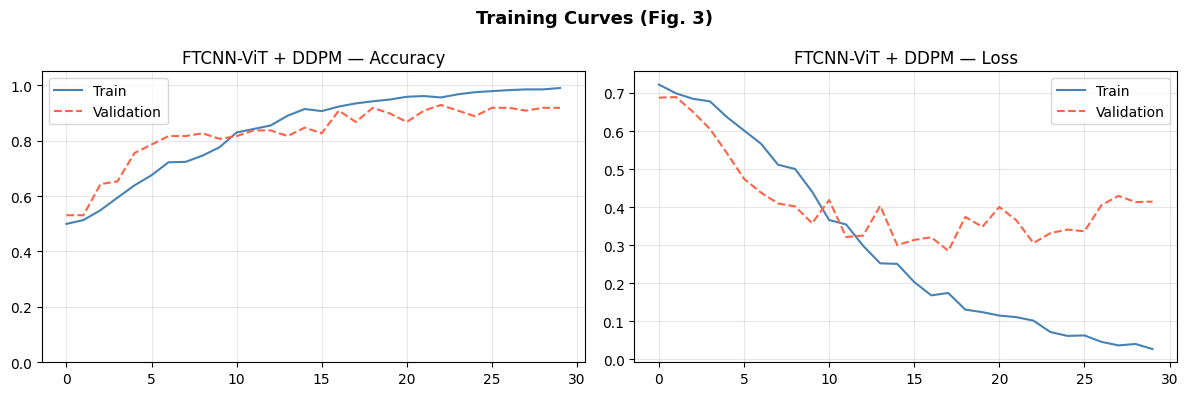

In [54]:
hd = hist.history
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(hd['accuracy'],     label='Train',      color='steelblue')
ax1.plot(hd['val_accuracy'], label='Validation', color='tomato', ls='--')
ax1.set_title('FTCNN-ViT + DDPM — Accuracy')
ax1.set_ylim([0, 1.05]); ax1.legend(); ax1.grid(alpha=0.3)

ax2.plot(hd['loss'],     label='Train',      color='steelblue')
ax2.plot(hd['val_loss'], label='Validation', color='tomato', ls='--')
ax2.set_title('FTCNN-ViT + DDPM — Loss')
ax2.legend(); ax2.grid(alpha=0.3)

plt.suptitle('Training Curves (Fig. 3)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'fig3_curves.png'), dpi=150)
plt.show()

## Cell 16 — Evaluation (Table V, Eq. 17-20)

In [55]:
def compute_metrics(y_true, y_prob, threshold=0.5):
    y_pred = (y_prob >= threshold).astype(int)
    tp = int(np.sum((y_pred==1) & (y_true==1)))
    tn = int(np.sum((y_pred==0) & (y_true==0)))
    fp = int(np.sum((y_pred==1) & (y_true==0)))
    fn = int(np.sum((y_pred==0) & (y_true==1)))
    acc  = (tp + tn) / (tp + tn + fp + fn + 1e-9)
    prec = tp / (tp + fp + 1e-9)
    rec  = tp / (tp + fn + 1e-9)
    f1   = 2 * prec * rec / (prec + rec + 1e-9)
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    return dict(
        acc=acc, prec=prec, rec=rec, f1=f1,
        tp=tp, tn=tn, fp=fp, fn=fn,
        auc=auc(fpr, tpr), fpr=fpr, tpr=tpr,
        y_pred=y_pred, y_prob=y_prob
    )

y_prob = fusion_model.predict(X_test, verbose=0).ravel()
res    = compute_metrics(y_test, y_prob)

print(f'\n{"─"*60}')
print('  FTCNN-ViT + DDPM — Classification Report (Table V)')
print(f'{"─"*60}')
print(classification_report(y_test, res['y_pred'],
                             target_names=CLASSES, digits=4))
print(f'  Accuracy : {res["acc"]:.4f}')
print(f'  Precision: {res["prec"]:.4f}')
print(f'  Recall   : {res["rec"]:.4f}')
print(f'  F1-Score : {res["f1"]:.4f}')
print(f'  AUC      : {res["auc"]:.4f}')


────────────────────────────────────────────────────────────
  FTCNN-ViT + DDPM — Classification Report (Table V)
────────────────────────────────────────────────────────────
              precision    recall  f1-score   support

 No Accident     0.8305    0.9245    0.8750        53
    Accident     0.9024    0.7872    0.8409        47

    accuracy                         0.8600       100
   macro avg     0.8665    0.8559    0.8580       100
weighted avg     0.8643    0.8600    0.8590       100

  Accuracy : 0.8600
  Precision: 0.9024
  Recall   : 0.7872
  F1-Score : 0.8409
  AUC      : 0.9482


## Cell 17 — Confusion Matrix + ROC + PR Curve (Fig. 4 & 5)

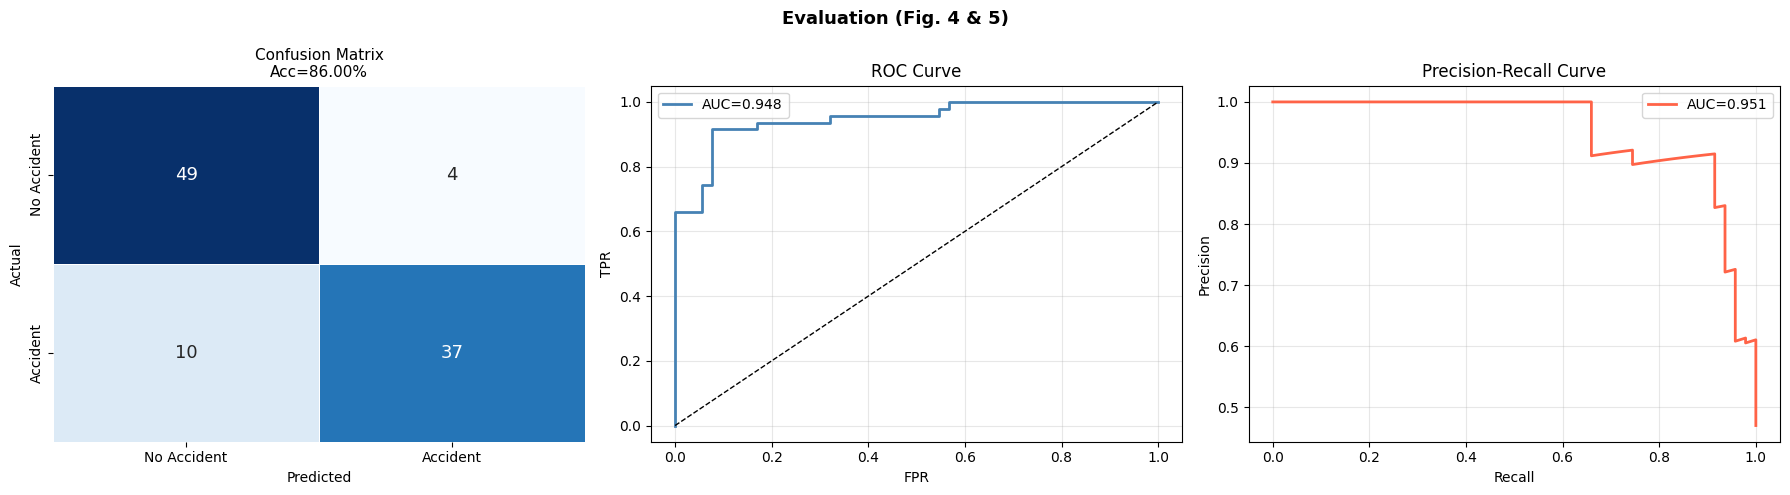

In [56]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Confusion Matrix
cm = confusion_matrix(y_test, res['y_pred'])
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASSES, yticklabels=CLASSES,
            ax=axes[0], cbar=False, linewidths=0.5, annot_kws={'size': 13})
axes[0].set_title(f'Confusion Matrix\nAcc={res["acc"]:.2%}', fontsize=11)
axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('Actual')

# ROC
axes[1].plot(res['fpr'], res['tpr'], color='steelblue', lw=2,
             label=f'AUC={res["auc"]:.3f}')
axes[1].plot([0,1], [0,1], 'k--', lw=1)
axes[1].set_xlabel('FPR'); axes[1].set_ylabel('TPR')
axes[1].set_title('ROC Curve'); axes[1].legend(); axes[1].grid(alpha=0.3)

# PR Curve
prec_c, rec_c, _ = precision_recall_curve(y_test, res['y_prob'])
pr_auc = auc(rec_c, prec_c)
axes[2].plot(rec_c, prec_c, color='tomato', lw=2, label=f'AUC={pr_auc:.3f}')
axes[2].set_xlabel('Recall'); axes[2].set_ylabel('Precision')
axes[2].set_title('Precision-Recall Curve'); axes[2].legend(); axes[2].grid(alpha=0.3)

plt.suptitle('Evaluation (Fig. 4 & 5)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'fig4_5_eval.png'), dpi=150)
plt.show()

## Cell 18 — Grad-CAM Saliency Maps

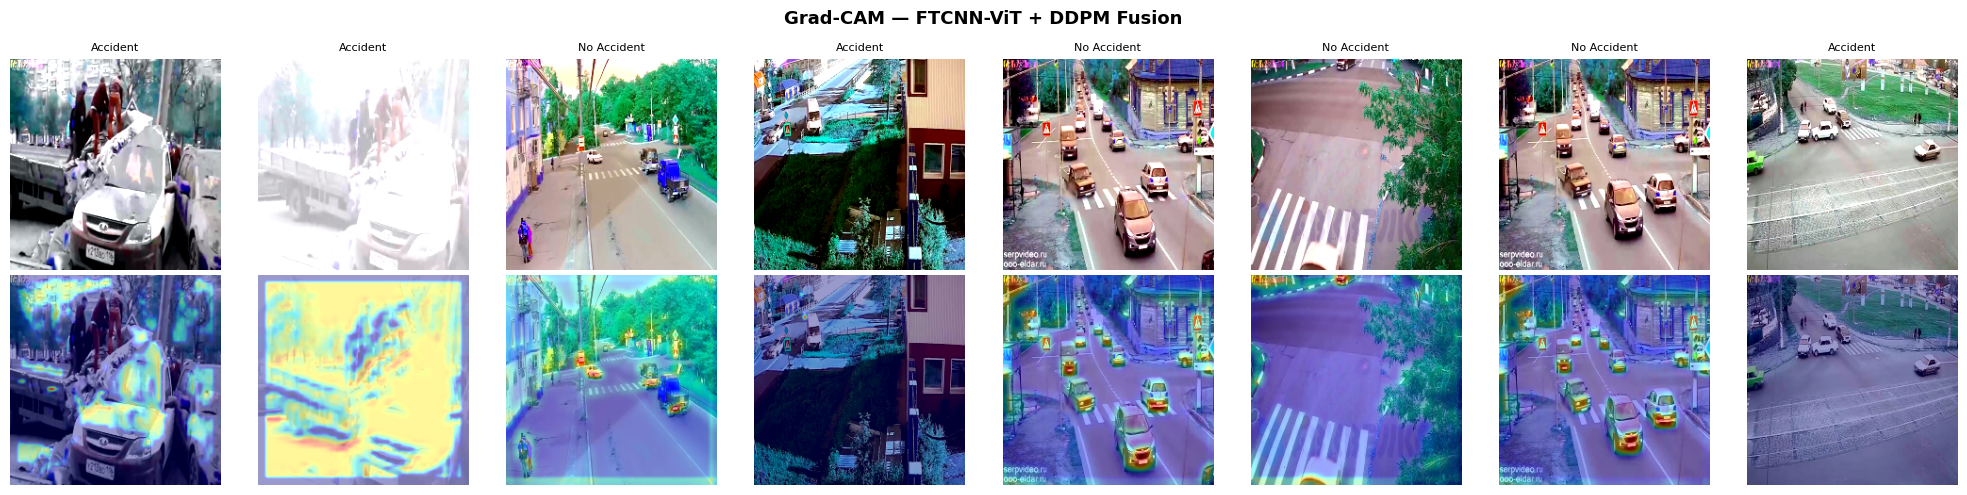

In [57]:
def grad_cam(model, img_array, last_conv='ftcnn_conv3'):
    gm = tf.keras.Model(
        inputs=model.inputs,
        outputs=[model.get_layer(last_conv).output, model.output]
    )
    batch = np.expand_dims(img_array, 0).astype(np.float32)
    with tf.GradientTape() as tape:
        conv_out, preds = gm(batch)
        loss = preds[:, 0]
    grads = tape.gradient(loss, conv_out)
    w   = tf.reduce_mean(grads, axis=(0, 1, 2))
    cam = tf.reduce_sum(w * conv_out[0], axis=-1).numpy()
    cam = np.maximum(cam, 0)
    cam = cam / (cam.max() + 1e-8)
    cam = cv2.resize(cam, (CLF_W, CLF_H))
    hm  = cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET)
    orig = np.uint8(255 * img_array[:, :, ::-1])
    ov   = cv2.addWeighted(orig, 0.6, hm, 0.4, 0)
    return cv2.cvtColor(ov, cv2.COLOR_BGR2RGB)

n_show = 8
fig, axes = plt.subplots(2, n_show, figsize=(2.5 * n_show, 5))
for i in range(n_show):
    axes[0, i].imshow(X_test[i])
    axes[0, i].axis('off')
    axes[0, i].set_title(CLASSES[y_test[i]], fontsize=8)
    axes[1, i].imshow(grad_cam(fusion_model, X_test[i]))
    axes[1, i].axis('off')
    if i == 0:
        axes[0, i].set_ylabel('Original',  fontsize=9)
        axes[1, i].set_ylabel('Grad-CAM',  fontsize=9)

plt.suptitle('Grad-CAM — FTCNN-ViT + DDPM Fusion', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'gradcam.png'), dpi=150)
plt.show()

## Cell 19 — Final Summary

In [58]:
r = res
print('\n' + '='*65)
print('  FINAL RESULTS — DDPM + FTCNN-ViT Fusion')
print('  Xi et al. IEEE TITS 2025 (Diffusion-augmented reproduction)')
print('='*65)
print(f'  Accuracy : {r["acc"]:.4f}   (paper target >= 0.95)')
print(f'  Precision: {r["prec"]:.4f}   (paper target >= 0.98)')
print(f'  Recall   : {r["rec"]:.4f}   (paper target >= 0.92)')
print(f'  F1-Score : {r["f1"]:.4f}   (paper target >= 0.95)')
print(f'  AUC      : {r["auc"]:.4f}')
print('='*65)
print(f'\nOutputs saved to: {OUTPUT_DIR}')
for ff in sorted(os.listdir(OUTPUT_DIR)):
    print(f'  {ff}')


  FINAL RESULTS — DDPM + FTCNN-ViT Fusion
  Xi et al. IEEE TITS 2025 (Diffusion-augmented reproduction)
  Accuracy : 0.8600   (paper target >= 0.95)
  Precision: 0.9024   (paper target >= 0.98)
  Recall   : 0.7872   (paper target >= 0.92)
  F1-Score : 0.8409   (paper target >= 0.95)
  AUC      : 0.9482

Outputs saved to: /kaggle/working/outputs
  FTCNN_ViT_history.csv
  ddpm_loss_curve.png
  ddpm_samples.png
  fig3_curves.png
  fig4_5_eval.png
  gradcam.png
